# PEFT Showdown: results analysis

Loads every result JSON in `results/final/` and produces:

- `analysis/unified_table.md` / `.csv`: all methods x tasks x regimes, plus efficiency
- `analysis/low_data_table.md`: accuracy lost going from full data to 1k examples
- `analysis/figures/*.png`: the four plots for the report

Works with any subset of methods, so it can be re-run as results arrive.
Run it from the repo root or from `analysis/`. Scores are GLUE validation, mean ± std over seeds, x100.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.results import METHODS, TASKS, load_results

OUT = ROOT / "analysis"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

NAMES = {"full_ft": "Full FT", "lora": "LoRA", "adapter": "Adapters",
         "prompt_tuning": "Prompt tuning"}
TASK_NAMES = {"sst2": "SST-2", "mrpc": "MRPC", "rte": "RTE"}
REGIMES = ["full", "1k"]
COLORS = dict(zip(METHODS, plt.get_cmap("tab10").colors))
EXPECTED_RUNS = 16  # per method, see issue #25

df = load_results("final", root=ROOT / "results")
methods = [m for m in METHODS if m in set(df["method"])]
print(f"{len(df)} runs, methods: {[NAMES[m] for m in methods]}")

17 runs, methods: ['Full FT', 'LoRA']


## Run counts
Each method should have 16 runs: RTE/MRPC full and 1k x 3 seeds, SST-2 1k x 3 seeds, SST-2 full x 1 seed.

In [2]:
counts = (df.groupby(["method", "task", "regime"]).size()
            .unstack(["task", "regime"]).reindex(methods).fillna(0).astype(int))
counts["total"] = counts.sum(axis=1)
for m, n in counts["total"].items():
    if n != EXPECTED_RUNS:
        print(f"WARNING: {NAMES[m]} has {n} runs, expected {EXPECTED_RUNS}")
counts

C:\Users\hp\AppData\Local\Temp\ipykernel_8792\2050680974.py:3: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  counts["total"] = counts.sum(axis=1)


task    mrpc      rte      sst2      total
regime    1k full  1k full   1k full      
method                                    
full_ft    3    3   3    3    3    1    16
lora       0    0   1    0    0    0     1

## Unified table

In [3]:
def mean_std(s):
    s = s.dropna() * 100
    if len(s) == 0:
        return "–"
    if len(s) == 1:
        return f"{s.iloc[0]:.1f}"
    return f"{s.mean():.1f} ± {s.std(ddof=1):.1f}"


def num(s, fmt):
    if np.isscalar(s):
        return "–" if pd.isna(s) else format(s, fmt)
    s = s.dropna()
    return format(s.mean(), fmt) if len(s) else "–"


rows = []
for m in methods:
    d = df[df["method"] == m]
    row = {"Method": NAMES[m]}
    for t in TASKS:
        for r in REGIMES:
            x = d[(d["task"] == t) & (d["regime"] == r)]
            label = f"{TASK_NAMES[t]} {r}"
            row[f"{label} acc"] = mean_std(x["metrics.accuracy"])
            if t == "mrpc":
                row[f"{label} F1"] = mean_std(x["metrics.f1"])
    eff = lambda c: d[c].dropna()
    row["Trainable params"] = f"{int(eff('efficiency.trainable_params').median()):,}"
    row["% trainable"] = f"{eff('efficiency.trainable_pct').median():.2f}"
    row["Peak mem (MiB)"] = num(eff("efficiency.peak_gpu_mem_mb").max(), ".0f")
    for t in ("rte", "sst2"):
        x = d[(d["task"] == t) & (d["regime"] == "full")]["efficiency.train_time_s"]
        row[f"Time {TASK_NAMES[t]} full (s)"] = num(x, ".0f")
    row["Checkpoint (MB)"] = f"{eff('efficiency.checkpoint_size_mb').median():.1f}"
    rows.append(row)

unified = pd.DataFrame(rows).set_index("Method")
unified.to_csv(OUT / "unified_table.csv")
(OUT / "unified_table.md").write_text(
    "Scores: GLUE validation, x100, mean ± std over seeds 1-3 "
    "(SST-2 full: seed 1 only). Peak memory: max over all runs. "
    "Times: Tesla T4, fp16, batch 32.\n\n"
    + unified.to_markdown() + "\n", encoding="utf-8")
unified.T

Method,Full FT,LoRA
SST-2 full acc,94.0,–
SST-2 1k acc,90.4 ± 0.5,–
MRPC full acc,87.7 ± 1.4,–
MRPC full F1,91.2 ± 1.2,–
MRPC 1k acc,85.8 ± 2.2,–
MRPC 1k F1,89.9 ± 1.4,–
RTE full acc,76.1 ± 2.2,–
RTE 1k acc,69.9 ± 2.1,70.4
Trainable params,"124,647,170","887,042"
% trainable,100.00,0.71


## Numeric summary
Means and standard deviations per method, task and regime (used by the plots).

In [4]:
cols = ["metrics.accuracy", "metrics.f1", "efficiency.peak_gpu_mem_mb",
        "efficiency.train_time_s"]
summary = df.groupby(["method", "task", "regime"])[cols].agg(["mean", "std", "count"])
summary.to_csv(OUT / "summary_numeric.csv")
summary

metrics.accuracy                 metrics.f1            \
                                mean       std count       mean       std   
method  task regime                                                         
full_ft mrpc 1k             0.857843  0.022464     3   0.898677  0.013835   
             full           0.877451  0.013646     3   0.912112  0.011668   
        rte  1k             0.699158  0.020528     3        NaN       NaN   
             full           0.760529  0.022058     3        NaN       NaN   
        sst2 1k             0.903670  0.005255     3        NaN       NaN   
             full           0.940367       NaN     1        NaN       NaN   
lora    rte  1k             0.703971       NaN     1        NaN       NaN   

                          efficiency.peak_gpu_mem_mb                   \
                    count                       mean        std count   
method  task regime                                                     
full_ft mrpc 1k         3                2918.700000  77.507354     3   
             full       3                2973.100000   9.591142     3   
        rte  1k         0                3264.400000   0.000000     3   
             full       0                3264.400000   0.000000     3   
        sst2 1k         0                2401.633333  29.338428     3   
             full       0                2487.300000        NaN     1   
lora    rte  1k         0                1937.200000        NaN     1   

                    efficiency.train_time_s                  
                                       mean       std count  
method  task regime                                          
full_ft mrpc 1k                  149.233333  6.924112     3  
             full                162.700000  1.539480     3  
        rte  1k                  167.533333  5.415102     3  
             full                158.133333  0.057735     3  
        sst2 1k                  185.400000  3.593049     3  
             full                491.800000       NaN     1  
lora    rte  1k                  118.100000       NaN     1

## Low-data regime
Accuracy points lost when training on 1k examples instead of the full training set. Smaller is better.

In [5]:
acc = df.groupby(["method", "task", "regime"])["metrics.accuracy"].mean().mul(100)
low_rows = []
for m in methods:
    row = {"Method": NAMES[m]}
    drops = []
    for t in TASKS:
        try:
            full, few = acc[(m, t, "full")], acc[(m, t, "1k")]
        except KeyError:
            row[TASK_NAMES[t]] = "–"
            continue
        drops.append(full - few)
        row[TASK_NAMES[t]] = f"{full:.1f} → {few:.1f} ({few - full:+.1f})"
    row["Mean drop"] = f"{np.mean(drops):.1f}" if drops else "–"
    low_rows.append(row)
low = pd.DataFrame(low_rows).set_index("Method")
(OUT / "low_data_table.md").write_text(
    "Validation accuracy x100, full data → 1k examples (change). Mean over seeds.\n\n"
    + low.to_markdown() + "\n", encoding="utf-8")
low

,SST-2,MRPC,RTE,Mean drop
Method,,,,
Full FT,94.0 → 90.4 (-3.7),87.7 → 85.8 (-2.0),76.1 → 69.9 (-6.1),3.9
LoRA,–,–,–,–


## Plot 1: accuracy vs trainable parameters (full data)

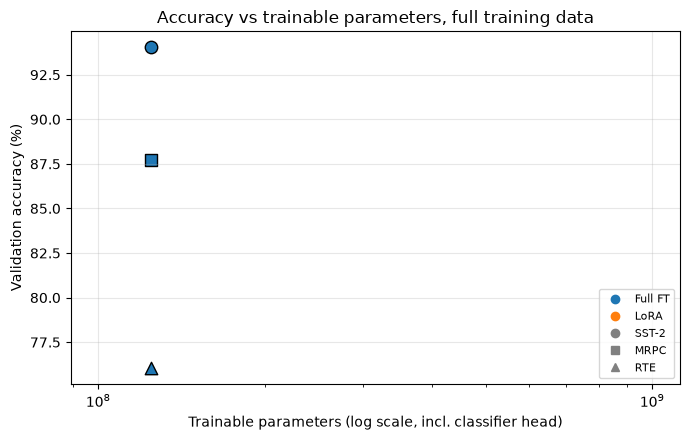

In [6]:
markers = {"sst2": "o", "mrpc": "s", "rte": "^"}
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in methods:
    for t in TASKS:
        x = df[(df["method"] == m) & (df["task"] == t) & (df["regime"] == "full")]
        if x.empty:
            continue
        ax.scatter(x["efficiency.trainable_params"].median(),
                   x["metrics.accuracy"].mean() * 100,
                   color=COLORS[m], marker=markers[t], s=80, edgecolor="black")
ax.set_xscale("log")
ax.set_xlabel("Trainable parameters (log scale, incl. classifier head)")
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Accuracy vs trainable parameters, full training data")
method_handles = [plt.Line2D([], [], marker="o", ls="", color=COLORS[m], label=NAMES[m])
                  for m in methods]
task_handles = [plt.Line2D([], [], marker=markers[t], ls="", color="gray",
                           label=TASK_NAMES[t]) for t in TASKS]
ax.legend(handles=method_handles + task_handles, fontsize=8, loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "acc_vs_params.png", dpi=150)
plt.show()

## Plot 2: full data vs 1k examples

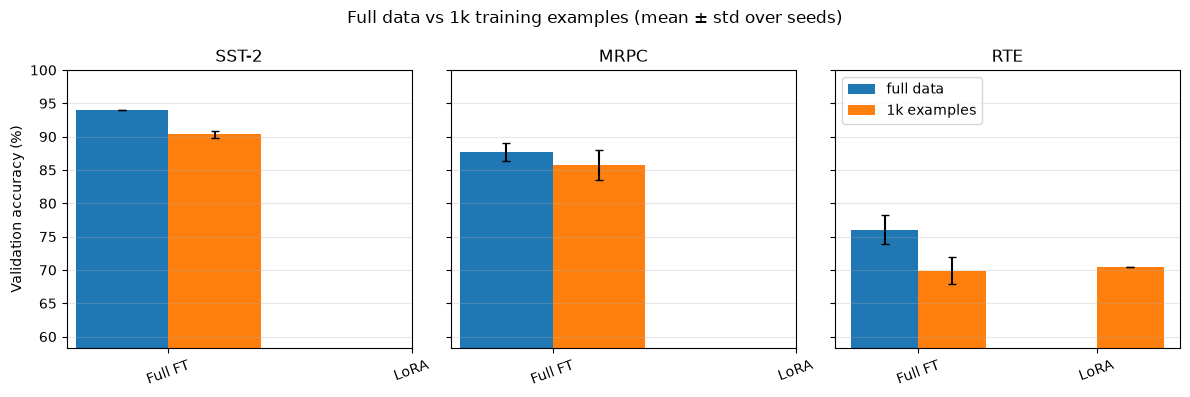

In [7]:
fig, axes = plt.subplots(1, len(TASKS), figsize=(12, 4), sharey=True)
width = 0.38
for ax, t in zip(axes, TASKS):
    xs = np.arange(len(methods))
    for k, r in enumerate(REGIMES):
        means, stds = [], []
        for m in methods:
            s = df[(df["method"] == m) & (df["task"] == t) & (df["regime"] == r)]["metrics.accuracy"] * 100
            means.append(s.mean() if len(s) else np.nan)
            stds.append(s.std(ddof=1) if len(s) > 1 else 0)
        ax.bar(xs + (k - 0.5) * width, means, width, yerr=stds, capsize=3,
               label="full data" if r == "full" else "1k examples",
               color="tab:blue" if r == "full" else "tab:orange")
    ax.set_xticks(xs, [NAMES[m] for m in methods], rotation=20)
    ax.set_title(TASK_NAMES[t])
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Validation accuracy (%)")
lo = np.nanmin(df["metrics.accuracy"]) * 100
axes[0].set_ylim(max(0, lo - 10), 100)
axes[-1].legend()
fig.suptitle("Full data vs 1k training examples (mean ± std over seeds)")
fig.tight_layout()
fig.savefig(FIG / "full_vs_1k.png", dpi=150)
plt.show()

## Plots 3 and 4: peak GPU memory and training time (full data)

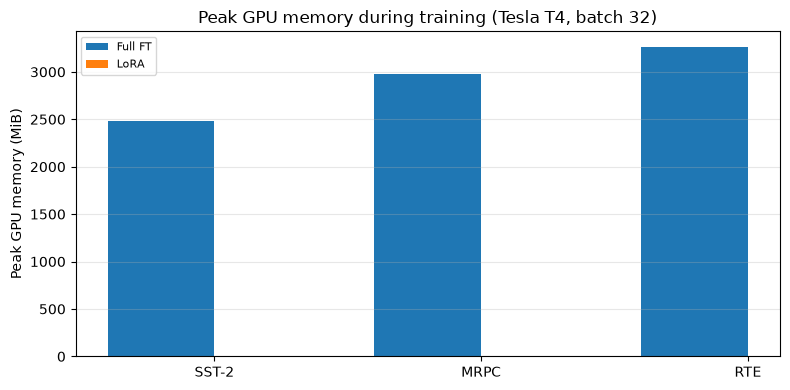

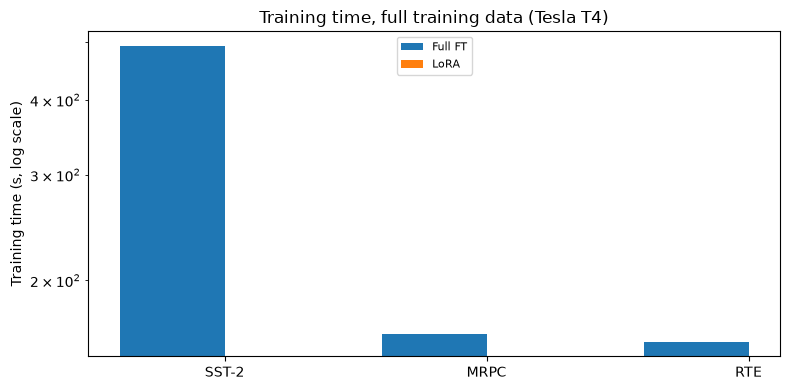

In [8]:
def grouped_bar(col, ylabel, title, fname, log=False):
    fig, ax = plt.subplots(figsize=(8, 4))
    width = 0.8 / max(len(methods), 1)
    xs = np.arange(len(TASKS))
    for k, m in enumerate(methods):
        vals = [df[(df["method"] == m) & (df["task"] == t) & (df["regime"] == "full")][col].mean()
                for t in TASKS]
        ax.bar(xs + (k - (len(methods) - 1) / 2) * width, vals, width,
               label=NAMES[m], color=COLORS[m])
    ax.set_xticks(xs, [TASK_NAMES[t] for t in TASKS])
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if log:
        ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG / fname, dpi=150)
    plt.show()


grouped_bar("efficiency.peak_gpu_mem_mb", "Peak GPU memory (MiB)",
            "Peak GPU memory during training (Tesla T4, batch 32)", "peak_memory.png")
grouped_bar("efficiency.train_time_s", "Training time (s, log scale)",
            "Training time, full training data (Tesla T4)", "train_time.png", log=True)